# **Assignment 4: MCMC**

### **The goal of Assignment 4 is to develop a general, flexible MCMC that can be used to fit models to data and then to apply this MCMC to real astrophysics data.**

Our notebook covers the following:

**1) Background Information**: This covers the purpose of the project and explains relevant vocabulary, equations, and concepts.

**2) General MCMC (Linear, Two Parameters):** This code produces a generalized MCMC that can fit a linear model with two parameters (slope and y-intercept) to a two-dimensional data set. It assumes the prior distributions are normal.

**3) General MCMC (Quadratic, Four Parameters):** This code produces a generalized MCMC that can fit a quadratic model with four parameters to a two-dimensional data set. It assumes the prior distributions are normal.

**4) Astrophysics MCMC:** This code produces an MCMC specifically designed to fit a sine curve to the spot flux data from CM Draconis. It assumes the prior distributions are "top hats" (limiting the function values to a certain range but with no preference towards any values in that range).

# **1) Background Information**

So, what exactly are we trying to do? And what is an MCMC, anyway?

Let's say we have data that depicts some kind of relationship between two variables and we want to find some way to model and quantify that relationship. We could draw a line connecting each and every point and call that our "model," but that wouldn't be particularly helpful - we want some kind of simpler function or distribution instead. Some questions might come up:

- If there looks to be a linear relationship between our variables, what's the best slope and y-intercept to make a line that fits that relationship? If there appears to be a sinusoidal relationship, then what's the best amplitude and period to use?
- What happens when I try out different parameters for my model that aren't quite the best?
- How does my prior knowledge about the data factor into my model?

**The Metropolis algorithm is an MCMC (Markov Chain Monte Carlo) method that can answer all of these questions. The purpose of an MCMC is to find the best model to fit your data *and* to display how slight changes to your model parameters can change that fit. It also allows you the option to input your prior knowledge about the data and shifts your model accordingly.**

**Below, we can take you step-by-step to admire the beauty of how it works.**

# **2) General MCMC for Linear Model (Two Parameters)**

Let's start by making a generalized MCMC that can be used to fit a linear model to two-dimensional data.

**Our MCMC is going to test different values for slope and y-intercept in order to determine the best line that fits our data. This relies on Bayes' Theorem, included below:

**Bayes' Theorem: $P(\theta|x) = \Large\frac{P(x|\theta)P(\theta)}{P(x)}$**

This theorem is fundamental to our MCMC and calculates the **posterior.** The definition of this term and all other relevant terms are as follows:

- **Model and Parameters:** This is some function/distribution that's going to be used to describe the data (e.g., linear, quadratic, normal, trigonometric, etc.). The goal of MCMC is to test different model **parameters** (e.g., slope and y-intercept) in order to find the best parameter values to fit the model to the data. Note that the end goal is NOT to create an overly complicated model that hits every single data point, since then there is no point to the model in the first place! **This generalized MCMC will fit a linear model to data with the slope and y-intercept as parameters.**

- **Evidence ($P(x)$):** This is used a normalization constant. When comparing posteriors, you don't need it.

- **Likelihood ($P(x|\theta)$):** This is the probability that a particular model (with specific parameters) produces the given data. In order to calculate the likelihood that our model produces ALL of the data, then we need to multiply each of the data point's individual probabilities together. This is calculated as $$L = \prod_{i=0}^{n}p(x_i|\theta) $$

  This results in a very small number, so to make things easier for us, we can take the log of this likelihood value.

- **Prior ($P(\theta)$):** This is the probability that our model occurs. This is where our PRIOR KNOWLEDGE/BELIEF comes into play! We can use any distribution here; it's essentially just a metric of how confident we are that our model happens. If we have no idea what the parameters are going to be, we can set equal probabilities to every possible parameter value; this is called a *flat prior*. In this example, we'll set up normal distributions as our priors for both slope and y-intercept.

- **Posterior ($P(\theta|x)$):** This is the probability that our evidence produces our model.

**The posterior is what we want to find, using Bayes' Theorem. The higher the value of the posterior, the better this model is for fitting our data.**

**So let's start off by seeing how we can calculate this posterior by creating a Python function! Let's assume that we have data that seem to resemble a linear relationship, and we want to find the optimal values for the slope (m) and the y-intercept (b).**

P.S. You can choose any letter to represent slope and y-intercept, but please refer to the map below:
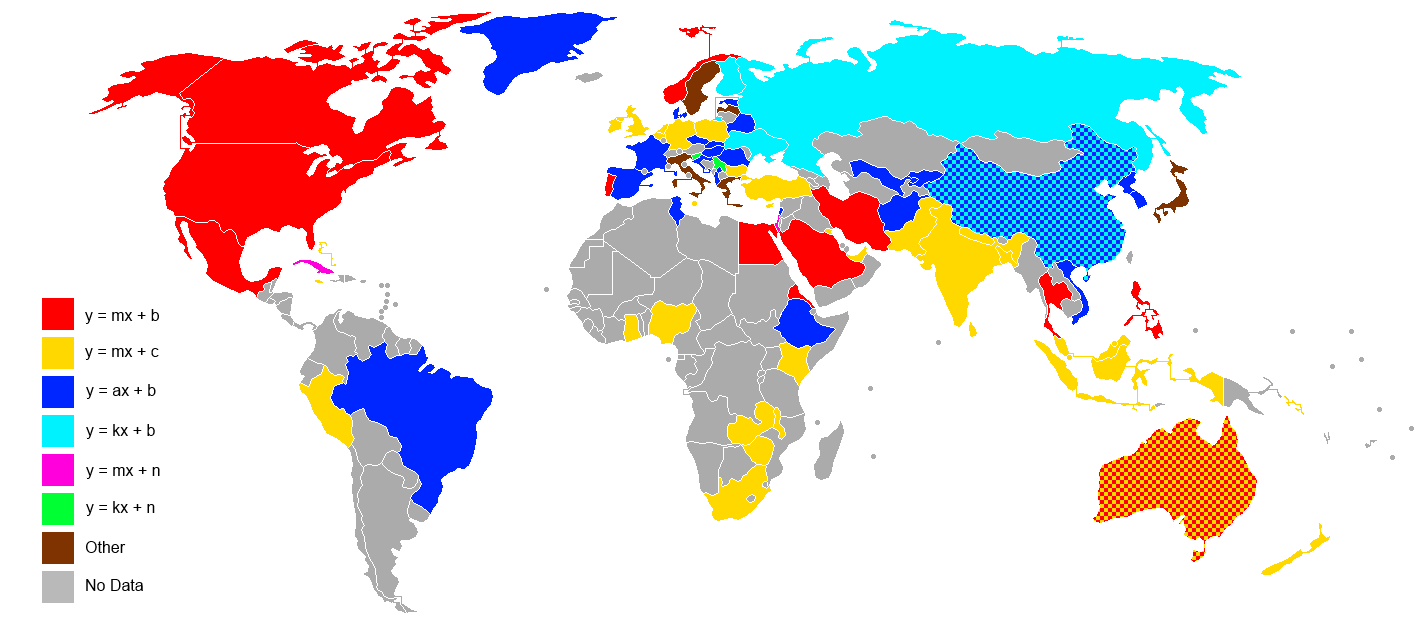

If you're Australian, we understand that you probably use "c" for the y-intercept, but we'll stick with "b" because we're in the U.S.

**The following code establishes an MCMC for fitting a line, y = mx + b, to a two-dimensional data set. The function `run_MCMC` takes in your data and allows you to customize how your MCMC runs; see below for the meaning of each variable. Note that `run_MCMC` assumes that your priors for m and b are both normal distributions.**

**`run_MCMC(x_data, y_data, error, starting_m, starting_b, prior_m_mean, prior_m_stdev, prior_b_mean, prior_b_stdev, jump_m_stdev, jump_b_stdev, N)`**

- `x_data`: x-values of 2d data, stored in an array
- `y_data`: y-values of 2d data, stored in an array
- `error`: error for each data point, stored in an array
- `starting_m`: m value to start the MCMC at
- `starting_b`: b value to start the MCMC at
- `prior_m_mean`: mean of prior distribution for m
- `prior_m_stdev`: standard deviation of prior distribution for m
- `prior_b_mean`: mean of prior distribution for b
- `prior_b_stdev`: standard deviation of prior distribution for b
- `jump_m_stdev`: standard deviation of jump function for m
- `jump_b_stdev`: standard deviation of jump function for b
- `N`: number of times MCMC runs


**Keep in mind:**
- The x-data, y-data, and error inputs all must be arrays of the same length in order for the MCMC to work. The error cannot be inputted as a constant.
- Try to choose values for starting_m and starting_b that you think are close to the actual values.
- The jump function operates by using a normal distribution centered at the current m value for the m jump and the current b value for the b jump. However, you can choose the standard deviation of both of these normal distributions using jump_m_stdev and jump_b_stdev. A greater standard deviation will mean that bigger jumps are more likely.
- It is up to you to determine the best normal distributions to use as your priors for m and b. If you expect m to be between 10 and 20, for example, you could establish prior_m_mean as 15 and prior_m_stdev = 2.5 so that about 95% of the possible m-values fall between 10 and 20.

**MOST IMPORTANT NOTES**:
- **If you choose values extremely far from m and b for `starting_m` and `starting_b` and not a high enough value of `N`, your model might not reasonably fit your data.**
- **If you choose a prior distribution that is far away from the values of m and b that most closely fit a line to your data, then you're going to get a model that appears to be far away from your data. Don't fret: that's how an MCMC is supposed to work!**
- **Try running the MCMC a few times to see how the model changes! Sometimes the MCMC might get stuck at a bad posterior, so it's worth experimenting with multiple runs.**

In [11]:
# Import relevant packages
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from scipy.stats import binom,norm
import scipy
import pandas as pd

In [12]:
# Step 1: Define the calculate_posterior function.

def calculate_posterior(x_data, y_data, error, starting_m, starting_b, prior_m_mean, prior_m_stdev, prior_b_mean, prior_b_stdev):
  # Initialize loglikelihood.
  loglikelihood = 0

  # Calculate the log likelihood.
  for ii in range(len(x_data)):
    predicted_y = starting_m * x_data[ii] + starting_b
    likelihood_onepoint = norm.pdf(y_data[ii], predicted_y, error[ii])
    if likelihood_onepoint == 0:
      loglikelihood_onepoint = np.log10(10**-99) # assuming that when likelihood_onepoint = 0, it's actually rounding to 0 from a very small number such as ~ 10^(-99) (note that a normal distribution can't actually ever be 0)
    else:
      loglikelihood_onepoint = np.log10(likelihood_onepoint)
    loglikelihood += loglikelihood_onepoint

  # Calculate prior for m.
  prior_m = norm.pdf(starting_m, prior_m_mean, prior_m_stdev)
  logprior_m = np.log10(prior_m)

  # Calculate prior for b.
  prior_b = norm.pdf(starting_b, prior_b_mean, prior_b_stdev)
  logprior_b = np.log10(prior_b)

  # Calculate the posterior by ADDING the likelihood and the priors.
  logposterior = loglikelihood + logprior_m + logprior_b

  return logposterior

A lot has happened here, so let's dissect it! **First, we took our data and calculated the likelihood.** We do this by calculating the chance of us getting that data point given that we follow a particular model.

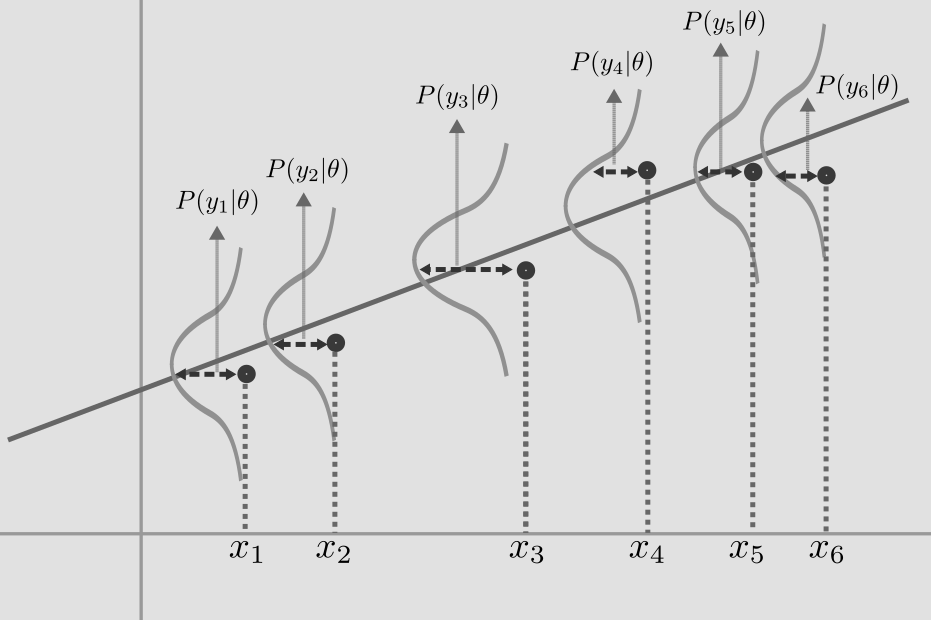




We calculate this by setting up a normal distribution where the mean is our predicted y value and the standard deviation is the error. Here, the likelihood of a particular data point is simply the value of this distribution at the observed y value. **We then calculate the likelihood of this entire model by multiplying the separate likelihoods of all these data points together.**

Of course, this value is going to be really really small as the number of data points increases. To help us deal with these numbers easier, we can take the log of the likelihood, which we did in the function above. **So, we ultimately have to ADD our likelihoods instead of multiplying to get our log likelihood for all data points.**

**Then. the posterior can be calculated: it's the product of the likelihood and priors of a given model (again, addition in logspace).**

**Now we can move on to the dark magic: the jump function.**

**In a Metropolis algorithm, we establish a starting model and then hop around different models and test for their respective posteriors.** If it's a better posterior, then we always (100% of the time) jump to that model. Interestingly, if it's worse, there's still a non-zero chance we jump to that model. This helps us explore around the maximum aposteriori (the posterior of the best model).

Below we define how much we jump each time. We set this to be a normal distribution of a set standard deviation for each parameter, with the mean at the previous "m" and "b". **Jump too far and you might go from a really good model to a terrible one in one single jump, but jump too little and you'll be really inefficient in exploring the parameter space.** So therefore, the standard deviation here is flexible and up to your discretion.

In [13]:
# Define the jump function.
def jump(starting_m, starting_b, jump_m_stdev, jump_b_stdev):
  jump_m = np.random.normal(starting_m, jump_m_stdev)
  jump_b = np.random.normal(starting_b, jump_b_stdev)
  return jump_m, jump_b

**Now we can move on to what we've all been waiting for: the MCMC function.**

In [14]:
def run_MCMC(x_data, y_data, error, starting_m, starting_b, prior_m_mean, prior_m_stdev, prior_b_mean, prior_b_stdev, jump_m_stdev, jump_b_stdev, N):

  # Calculate the posterior for our starting values of m and b.
  originallogposterior = calculate_posterior(x_data, y_data, error, starting_m, starting_b, prior_m_mean, prior_m_stdev, prior_b_mean, prior_b_stdev)

  # Create arrays to store the different jumps and their respective posteriors, as well as how many times we jumped.
  logposterior_array = [originallogposterior]
  m_array = [starting_m]
  b_array = [starting_b]
  jump_count = 0

  # Time to jump and see if we accept the new posterior!
  for ii in range(N):

    # Jump to a new m and a new b.
    new_m, new_b = jump(starting_m, starting_b, jump_m_stdev, jump_b_stdev)

    # Calculate the posterior for these new values.
    newlogposterior = calculate_posterior(x_data, y_data, error, new_m, new_b, prior_m_mean, prior_m_stdev, prior_b_mean, prior_b_stdev)

    # Compare the new log posterior with the previous log posterior, which is the last entry in the logposterior_array.
    log_accept_ratio = newlogposterior - logposterior_array[-1]
    accept_ratio = 10 ** log_accept_ratio

    # Determine whether or not to accept the new posterior. If accepted, store the new posterior in logposterior_array and count this jump.
    # If not accepted, then don't jump here and jump again somewhere else.
    if accept_ratio > np.random.uniform():
      m_array.append(new_m)
      b_array.append(new_b)
      starting_m = new_m
      starting_b = new_b
      jump_count += 1
      logposterior_array.append(newlogposterior)

    # Find the best log posterior and its index.
    best_logposterior = max(logposterior_array)
    best_logposterior_index = np.argmax(logposterior_array)

    # Calculate how often the MCMC jumps.
    jump_percentage = jump_count / N * 100

  return best_logposterior, best_logposterior_index, jump_count, jump_percentage, m_array[best_logposterior_index], b_array[best_logposterior_index], m_array, b_array, logposterior_array

**Here we create a function that hops around different values for each parameter N times and provides us the values for m and b that have the highest posterior.**

As mentioned, if the new posterior is greater that the old one then we must jump to those new parameters. This becomes the starting place for our next jump If the new posterior is worse, then the probability of us jumping is determined by how much more worse that new posterior is, particularly:

 $$ P_{\rm accept} = \frac{Posterior_{\rm new}}{Posterior_{\rm old}} $$

 **We compare $P_{\rm accept}$ to a random number between 0 and 1 (exclusive).  Note that $P_{\rm accept}$ is greater than 1 when the new posterior is better than the old posterior, so it will always be accepted in that scenario.**

 **The function returns the following information:**
 - Best log posterior
 - Index of the best log posterior
 - Number of times the MCMC jumped
 - Percentage of time the MCMC jumped
 - Best m value
 - Best b value
 - Array of all m values jumped to (and starting m)
 - Array of all b values jumped to (and starting b)
 - Array of log posteriors for each jump (and starting log posterior)

**These outputs can be used to determine the best fitting line for your data, investigate the parameter space, and make a lot of cool plots.**

**Let's look at an example of us using this generalized MCMC function with some fun (fake) data!**

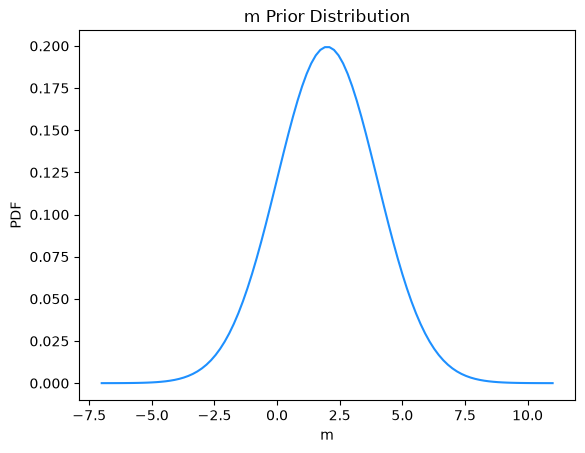

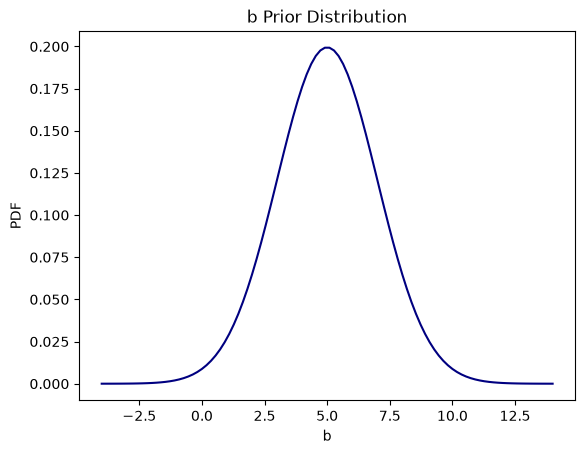

Jumped 275 out of 1000 times.
Optimal m: 2.085269614547214
Optimal b: 4.486962789800776


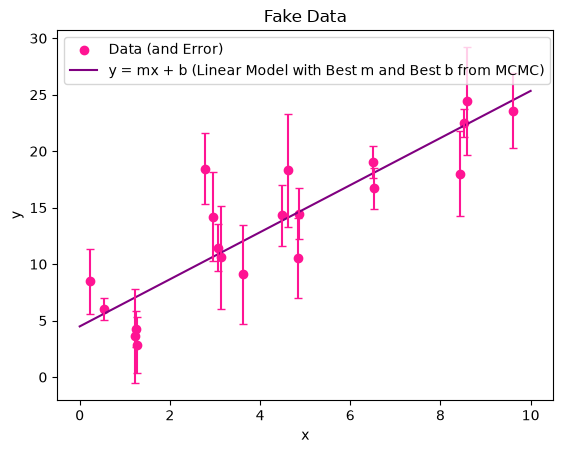

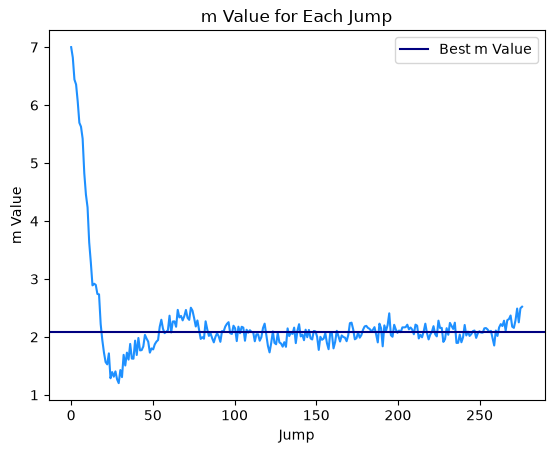

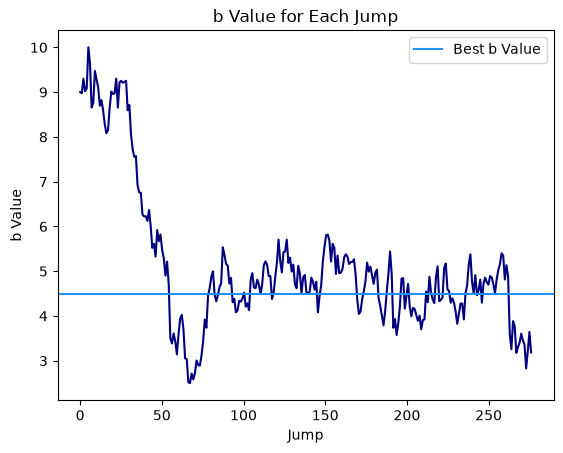

In [15]:
# Generate fake data (based on Class 8)

x_data = np.random.uniform(0,10,20) # create 20 data points randomly scattered along the x-axis between 0 and 10
truth_m = 2 # the true gradient of the line
truth_b = 5 # the true y-intercept of the line

def fake_data_function(x, m, b):
   y = m * x + b # line
   return y

y_data = fake_data_function(x_data, truth_m, truth_b)
error = np.linspace(1,5,len(x_data)) # error ranges from 1 to 5
y_data += np.random.normal(np.zeros(len(x_data)),error,len(x_data))

# Plot m prior as a normal distribution with mean = 2 and standard deviation = 2.
prior_m_mean = 2
prior_m_stdev = 2
x_values = np.linspace(-7,11,100)
plt.figure()
plt.plot(x_values, norm.pdf(x_values, prior_m_mean, prior_m_stdev), color = 'dodgerblue')
plt.title('m Prior Distribution')
plt.xlabel('m')
plt.ylabel('PDF')
plt.show()

# Plot b prior as normal distribution with mean = 5 and standard deviation = 2.
prior_b_mean = 5
prior_b_stdev = 2
x_values = np.linspace(-4,14,100)
plt.figure()
plt.plot(x_values, norm.pdf(x_values, prior_b_mean, prior_b_stdev), color = 'navy')
plt.title('b Prior Distribution')
plt.xlabel('b')
plt.ylabel('PDF')
plt.show()

# Let's start the MCMC with m = 7 and b = 9.
starting_m = 7
starting_b = 9
jump_m_stdev = 0.4
jump_b_stdev = 0.4

# Let's run the MCMC 1000 times.
N = 1000

# Print results.
results = run_MCMC(x_data, y_data, error, starting_m, starting_b, prior_m_mean, prior_m_stdev, prior_b_mean, prior_b_stdev, jump_m_stdev, jump_b_stdev, N)
print('Jumped ' + str(results[2]) + ' out of ' + str(N) + ' times.')
print('Optimal m: ' + str(results[4]))
print('Optimal b: ' + str(results[5]))

# Create a normalized_posterior_array from the logposterior_array for later plotting.
m = results[4]
b = results[5]
logposterior_array = results[8]
posterior_array = []
for ii in range(len(logposterior_array)):
  posterior = 10 ** logposterior_array[ii]
  posterior_array.append(posterior)

# Establish the model using the best m and best b determined by the MCMC.
x_values = np.linspace(0,10, 100)
best_posterior_model = m * x_values + b

# Plot observed data and results of MCMC
plt.figure()
plt.scatter(x_data, y_data, color = 'deeppink', label = "Data (and Error)")
plt.plot(x_values, best_posterior_model, color = 'purple', label = "y = mx + b (Linear Model with Best m and Best b from MCMC)")
plt.plot()
plt.errorbar(x_data, y_data, yerr = error, capsize = 3, color = 'deeppink', ls='none')
plt.legend(loc = 'upper left')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Fake Data')
plt.show()

# Plot how m changes with each jump.
plt.figure()
x_values = np.linspace(0, len(results[6]), len(results[6]))
plt.plot(x_values, results[6], color = 'dodgerblue')
plt.xlabel('Jump')
plt.ylabel('m Value')
plt.title('m Value for Each Jump')
plt.axhline(y = results[4], color = 'navy', label = 'Best m Value')
plt.legend(loc='best')
plt.show()


# Plot how b changes with each jump.
plt.figure()
x_values = np.linspace(0, len(results[7]), len(results[7]))
plt.plot(x_values, results[7], color = 'navy')
plt.xlabel('Jump')
plt.ylabel('b Value')
plt.title('b Value for Each Jump')
plt.axhline(y = results[5], color = 'dodgerblue', label = 'Best b Value')
plt.legend(loc='best')
plt.show()

**So we did it! We achieved an optimal value for m and b through our MCMC algorithm, which came out to be around ~2 for m and ~5 for b. We plotted this line and we can see that it goes through about 68% of our error bars, which is what we want!**

Note that the beginning of  our "m Value for Each Jump" plot starts very far away from the best m. **This starting portion is called "burn-in" and occurs because our starting guess for m is not close to the actual values.** b doesn't exhibit as much burn-in because it starts closer to the best value.

**As for our jumps, we jumped around 15-25% of the time, which is a good acceptance ratio.** This of course depends on what you set the standard deviation to be in the jump function, as lower standard deviations would result in a higher jumping percentage. Our jumps hover around the best m and b values as the MCMC progresses. But what if...we wanted to deal with more than 2 parameters?

# **3) General MCMC for Quadratic Model (Four Parameters)**

**This code follows the same process as our previous MCMC, but fits a quadratic function with four parameters (a, b, c, and d) instead of a linear function with two parameters. Our quadratic function is defined as $ y = a(x-d)^2 + bx + c$.** Note that the `run_MCMC` function now requires the following for a, b, c, and d: starting values, prior distributions, and jump distribution standard deviations.

The function now looks like:

`run_MCMC(x_data, y_data, error, starting_a, starting_b, starting_c, starting_d, prior_a_mean, prior_a_stdev, prior_b_mean, prior_b_stdev, prior_c_mean, prior_c_stdev, prior_d_mean, prior_d_stdev, jump_a_stdev, jump_b_stdev, jump_c_stdev, jump_d_stdev, N)`

Yes, it takes in 20 different variables! Have fun customizing, but don't get too carried away with extreme values or else the MCMC will not give you particularly helpful results.

Additional note: Technically, by using 4 variables, we are over-constraining our quadratic function. It could also just be calculated as `y = a(x-b)^2 + c`. As such, there may be some interesting covariance between our variables, but don't worry too much about that!

In [16]:
def calculate_posterior(x_data, y_data, error, starting_a, starting_b, starting_c, starting_d, prior_a_mean, prior_a_stdev, prior_b_mean, prior_b_stdev, prior_c_mean, prior_c_stdev, prior_d_mean, prior_d_stdev):
  loglikelihood = 0
  for ii in range(len(x_data)):
    predicted_y = starting_a * ((x_data[ii] - starting_d)**2) + starting_b * (x_data[ii]) + starting_c
    likelihood_onepoint = norm.pdf(y_data[ii], predicted_y, error[ii])
    if likelihood_onepoint == 0:
      loglikelihood_onepoint = np.log10(10**-99)
    else:
      loglikelihood_onepoint = np.log10(likelihood_onepoint)
    loglikelihood += loglikelihood_onepoint

  # calculate prior for a
  prior_a = norm.pdf(starting_a, prior_a_mean, prior_a_stdev)
  logprior_a = np.log10(prior_a)

  # calculate prior for b
  prior_b = norm.pdf(starting_b, prior_b_mean, prior_b_stdev)
  logprior_b = np.log10(prior_b)

  # calculate prior for c
  prior_c = norm.pdf(starting_c, prior_c_mean, prior_c_stdev)
  logprior_c = np.log10(prior_c)

  # calculate prior for d
  prior_d = norm.pdf(starting_d, prior_d_mean, prior_d_stdev)
  logprior_d = np.log10(prior_d)

  # calculate posterior using addition (because of logs)
  logposterior = loglikelihood + logprior_a + logprior_b + logprior_c + logprior_d

  return logposterior

Here, instead of only having the starting values for a and b and their respective prior means and standard deviations, we have to deal with twice as many variables.

In [17]:
def jump(starting_a, starting_b, starting_c, starting_d, jump_a_stdev, jump_b_stdev, jump_c_stdev, jump_d_stdev):
  jump_a = np.random.normal(starting_a, jump_a_stdev)
  jump_b = np.random.normal(starting_b, jump_b_stdev)
  jump_c = np.random.normal(starting_c, jump_c_stdev)
  jump_d = np.random.normal(starting_d, jump_d_stdev)
  return jump_a, jump_b, jump_c, jump_d

The jump function will also undergo some changes, as now there can be 4 different starting values and 4 different standard deviations to measure how far you jump each time.

In [18]:
def run_MCMC(x_data, y_data, error, starting_a, starting_b, starting_c, starting_d, prior_a_mean, prior_a_stdev, prior_b_mean, prior_b_stdev, prior_c_mean, prior_c_stdev, prior_d_mean, prior_d_stdev, jump_a_stdev, jump_b_stdev, jump_c_stdev, jump_d_stdev, N):

  originallogposterior = calculate_posterior(x_data, y_data, error, starting_a, starting_b, starting_c, starting_d, prior_a_mean, prior_a_stdev, prior_b_mean, prior_b_stdev, prior_c_mean, prior_c_stdev, prior_d_mean, prior_d_stdev)

  logposterior_array = [originallogposterior]
  a_array = [starting_a]
  b_array = [starting_b]
  c_array = [starting_c]
  d_array = [starting_d]
  jump_count = 0

  for ii in range(N):
    new_a, new_b, new_c, new_d = jump(starting_a, starting_b, starting_c, starting_d, jump_a_stdev, jump_b_stdev, jump_c_stdev, jump_d_stdev)
    newlogposterior = calculate_posterior(x_data, y_data, error, new_a, new_b, new_c, new_d, prior_a_mean, prior_a_stdev, prior_b_mean, prior_b_stdev, prior_c_mean, prior_c_stdev, prior_d_mean, prior_d_stdev)

    # compare new log posterior with previous log posterior, which is the last entry in the logposterior_array
    log_accept_ratio = newlogposterior - logposterior_array[-1]
    accept_ratio = 10 ** log_accept_ratio

    if accept_ratio > np.random.uniform():
      a_array.append(new_a)
      b_array.append(new_b)
      c_array.append(new_c)
      d_array.append(new_d)
      starting_a = new_a
      starting_b = new_b
      starting_c = new_c
      starting_d = new_d
      jump_count += 1
      logposterior_array.append(newlogposterior)

    best_logposterior = max(logposterior_array)
    best_logposterior_index = np.argmax(logposterior_array)

    jump_percentage = jump_count / N * 100

  return best_logposterior, best_logposterior_index, jump_count, jump_percentage, a_array[best_logposterior_index], b_array[best_logposterior_index], c_array[best_logposterior_index], d_array[best_logposterior_index], a_array, b_array, c_array, d_array, logposterior_array

The above code is essentially the exact same as the 2-parameter one, just that we introduced new variables.

Jumped 34 out of 1000 times.
Optimal a: 2.124925631504055
Optimal b: -0.45697036422343806
Optimal c: 0.8118560495888847
Optimal d: 4.891223206214609


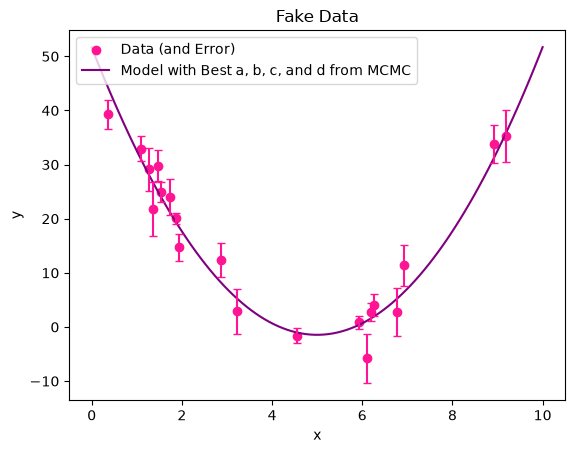

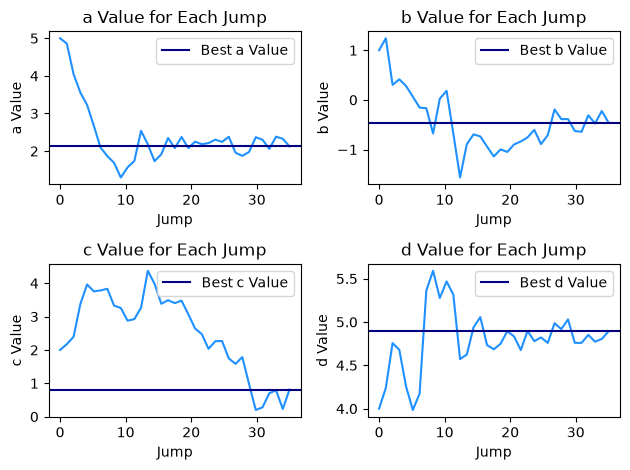

In [19]:
# Generate fake data (based on Class 8)
x_data = np.random.uniform(0,10,20) # create 20 data points randomly scattered along the x-axis between 0 and 10
truth_a = 2
truth_b = 0
truth_c = 1
truth_d = 5

def fake_data_function(x, a, b, c, d):
   y = (a * (x - d)**2) + b * x + c
   return y

y_data = fake_data_function(x_data, truth_a, truth_b, truth_c, truth_d)
error = np.linspace(1,5,len(x_data)) # error ranges between 1 and 5
y_data += np.random.normal(np.zeros(len(x_data)), error, len(x_data))

# Let's start the MCMC
starting_a = 5
starting_b = 1
starting_c = 2
starting_d = 4

# Let's run the MCMC 1000 times
N = 1000

prior_a_mean = 6
prior_a_stdev = 3
prior_b_mean = 0
prior_b_stdev = 2
prior_c_mean = 0
prior_c_stdev = 1
prior_d_mean = 8
prior_d_stdev = 3
jump_a_stdev = 0.5
jump_b_stdev = 0.5
jump_c_stdev = 0.5
jump_d_stdev = 0.5

results = run_MCMC(x_data, y_data, error, starting_a, starting_b, starting_c, starting_d, prior_a_mean, prior_a_stdev, prior_b_mean, prior_b_stdev, prior_c_mean, prior_c_stdev, prior_d_mean, prior_d_stdev, jump_a_stdev, jump_b_stdev, jump_c_stdev, jump_d_stdev, N)
print('Jumped ' + str(results[2]) + ' out of ' + str(N) + ' times.')
print('Optimal a: ' + str(results[4]))
print('Optimal b: ' + str(results[5]))
print('Optimal c: ' + str(results[6]))
print('Optimal d: ' + str(results[7]))

a = results[4]
b = results[5]
c = results[6]
d = results[7]
logposterior_array = results[12]
posterior_array = []
for ii in range(len(logposterior_array)):
  posterior = 10 ** logposterior_array[ii]
  posterior_array.append(posterior)

x_values = np.linspace(0,10, 100)
best_posterior_model = a * ((x_values - d)**2) + b * x_values + c

# Plot fake data and results of MCMC

plt.figure()
plt.scatter(x_data, y_data, color = 'deeppink', label = "Data (and Error)")
plt.plot(x_values, best_posterior_model, color = 'purple', label = "Model with Best a, b, c, and d from MCMC")
plt.plot()
plt.errorbar(x_data, y_data, yerr = error, color = 'deeppink', capsize = 3, ls = 'none')
plt.legend(loc = 'upper left')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Fake Data')
plt.show()

fig, axs = plt.subplots(2, 2)

# Plot how a changes with each jump.
x_values = np.linspace(0, len(results[8]), len(results[8]))
axs[0][0].plot(x_values, results[8], color = 'dodgerblue')
axs[0][0].set_xlabel('Jump')
axs[0][0].set_ylabel('a Value')
axs[0][0].set_title('a Value for Each Jump')
axs[0][0].axhline(y = results[4], color = 'navy', label = 'Best a Value')
axs[0][0].legend(loc='best')

# Plot how b changes with each jump.
x_values = np.linspace(0, len(results[9]), len(results[9]))
axs[0][1].plot(x_values, results[9], color = 'dodgerblue')
axs[0][1].set_xlabel('Jump')
axs[0][1].set_ylabel('b Value')
axs[0][1].set_title('b Value for Each Jump')
axs[0][1].axhline(y = results[5], color = 'navy', label = 'Best b Value')
axs[0][1].legend(loc='best')

# Plot how c changes with each jump.
x_values = np.linspace(0, len(results[10]), len(results[10]))
axs[1][0].plot(x_values, results[10], color = 'dodgerblue')
axs[1][0].set_xlabel('Jump')
axs[1][0].set_ylabel('c Value')
axs[1][0].set_title('c Value for Each Jump')
axs[1][0].axhline(y = results[6], color = 'navy', label = 'Best c Value')
axs[1][0].legend(loc='best')

# Plot how d changes with each jump.
x_values = np.linspace(0, len(results[11]), len(results[11]))
axs[1][1].plot(x_values, results[11], color = 'dodgerblue')
axs[1][1].set_xlabel('Jump')
axs[1][1].set_ylabel('d Value')
axs[1][1].set_title('d Value for Each Jump')
axs[1][1].axhline(y = results[7], color = 'navy', label = 'Best d Value')
axs[1][1].legend(loc='best')

fig.tight_layout()
plt.show()

# **4) Astrophysics MCMC**

Now that we have our generalized MCMC function, let's try to apply that to real exciting astrophysics data!

We will use data from Professor David Martin's paper on CM Draconis, an eclipsing binary star system. The following data depicts the change in spot modulation flux of CM Draconis with time (days). Spot modulation flux can be interpreted as a measure of brightness observed from the space telescope.

Let's plot the data first!

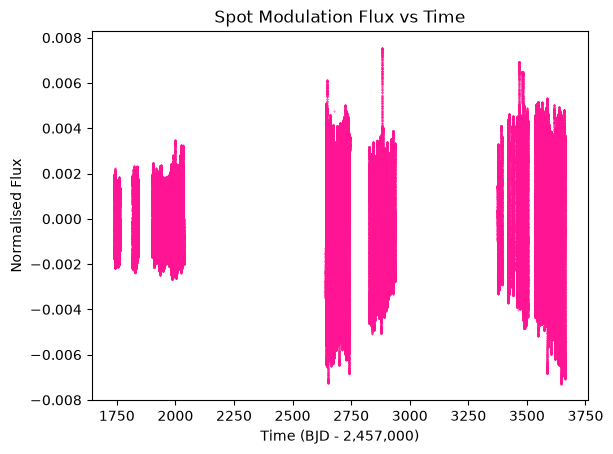

In [20]:
# Access time and flux columns of spot modulation file.
# Need to import spot_modulation.csv for this to work!

import os
if not os.path.exists('spot_modulation.csv'):
  raise FileNotFoundError("spot_modulation.csv not found. Upload it next to this notebook (in Colab: drag it into the Files panel on the left) and re-run this cell.")
spot_modulation = np.genfromtxt('spot_modulation.csv',delimiter=',')
spot_modulation = spot_modulation[~np.isnan(spot_modulation).any(axis=1)] # drop header or blank rows, if any
spot_time = spot_modulation[:,0]
spot_flux = spot_modulation[:,1]

# Plot of Spot Modulation Flux vs Time
plt.scatter(spot_time, spot_flux, s=0.1, color='deeppink')
plt.title('Spot Modulation Flux vs Time')
plt.xlabel('Time (BJD - 2,457,000)') # units = BJD - 2,457,000
plt.ylabel('Normalised Flux') # flux is normalised so there are no units
plt.show()

Woah, okay, that's a lot of data! Let's zoom in to the first group of data points (from time 1735 to 1765).

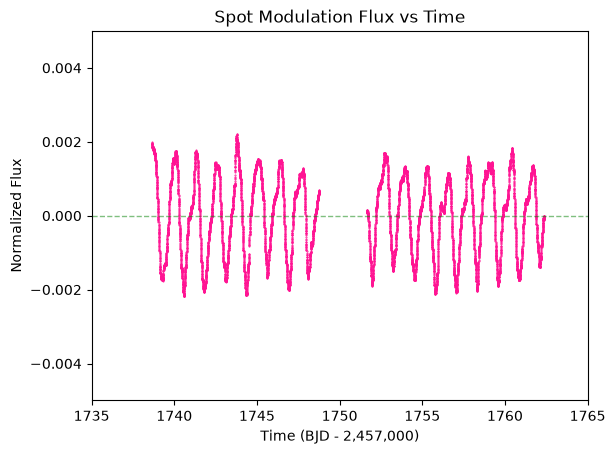

In [21]:
# Plot of spot modulation flux vs time in time interval [1735,1765]
plt.scatter(spot_time, spot_flux, s=0.2, color='deeppink')
plt.title('Spot Modulation Flux vs Time')
plt.xlabel('Time (BJD - 2,457,000)') # units = BJD - 2,457,000
plt.ylabel('Normalized Flux') # flux is normalised so there are no units
plt.xlim([1735,1765])
plt.ylim([-0.005,0.005])
plt.axhline(y=0, color='green', linestyle='--', linewidth=1, label='Horizontal Line at y=0', alpha = 0.5)
plt.show()

We can see that there are gaps in the data at times when the telescope wasn't recording any data. The spot modulation flux of CM Draconis fluctuates around 0 (since it's normalized), and **follows a seemingly sinusoidal pattern.**

**Our goal is to develop an MCMC algorithm to try to fit this data to a model. A typical sinusoidal function has 4 unknown parameters $(A,B,C,D)$:**

**$$f(x)=A\sin(B(x-C))+D$$**

where $A$ is the amplitude, $B$ is related to the period where $P = \frac{2π}{B}$, $C$ describes the horizontal shift and $D$ describes the vertical shift. However, since we already normalized the flux to oscillate around 0, we automatically recognize that $D=0$. Similarly, we can also assume $C=0$ since we can shift the starting point of these oscillations to the origin. Note that $ B = 2\p f$ (where f is the frequency), so we can use f instead of B.

**That leaves us with only two parameters to figure out, $A$ and $f$, with our function now being $f(x)=A\sin(2\pi fx)$.**

There is one slight problem here though: it is clear from our first graph that the amplitudes, or $A$, of the flux across different time frames are different. However, every chunk of data (separated by gaps) seems to have a consistent amplitude within itself. **We'll look at the first data frame from 1735 to 1765 (plotted above) and use our MCMC to obtain the best $A$ and $B$ values.**

In [22]:
# First, we have to find the indices in our array that include the data shown above (times before 1765).
end_index = np.searchsorted(spot_time, 1765)  # first index with time >= 1765
last_index = end_index - 1                    # index of the last point in this chunk
print(last_index) # 0 is the 1st index, so this chunk runs from index 0 up to last_index
print(spot_time[last_index], spot_time[last_index + 1]) # we can verify this by printing consecutive spot times: there is a jump (gap in the data) right after the chunk


14906
1762.3803727236 1816.0832774450523


In [23]:
# Now, we should shift our data so that it starts at the origin as a sinusoidal wave.
# We'll start by locating the first point at which it goes from negative to positive.
negtopos_index = []
for ii in range(0, last_index):
  current_value = spot_flux[ii]
  next_value = spot_flux[ii+1]
  if current_value < 0 and next_value > 0:
    negtopos_index.append(ii)
first_cross = negtopos_index[0]
print(f'The flux goes from negative to positive for the first time at time = {spot_time[first_cross]} BJD.')
print(f'The flux goes from {spot_flux[first_cross]} to {spot_flux[first_cross + 1]}.')


The flux goes from negative to positive for the first time at time = 1739.6750999405085 BJD.
The flux goes from -8.766534898230205e-06 to 1.4184494282698523e-05.


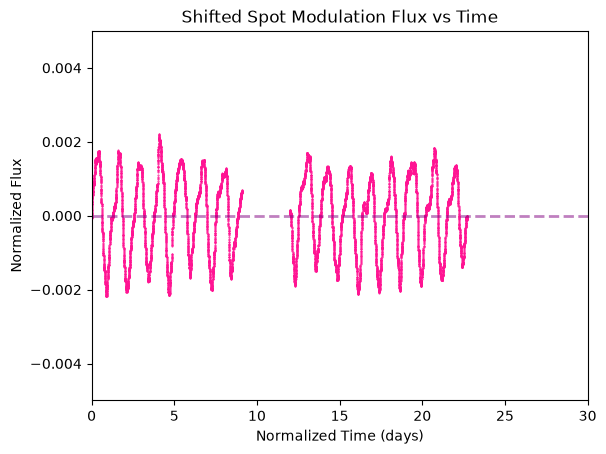

In [24]:
# Shift the spot flux so that it starts at the origin as a sinusoidal wave.
spot_flux1 = spot_flux[0:last_index + 1]
spot_time1 = spot_time[0:last_index + 1]
shifted_spot_time = spot_time1 - spot_time[first_cross]

# Plot of spot modulation flux vs time in time interval [1735,1765]
plt.scatter(shifted_spot_time, spot_flux1, s=0.2, color='deeppink')
plt.title('Shifted Spot Modulation Flux vs Time')
plt.xlabel('Normalized Time (days)') # units = BJD - 2,457,000
plt.ylabel('Normalized Flux') # flux is normalised so there are no units
plt.xlim([0,30])
plt.ylim([-0.005,0.005])
plt.axhline(y=0, color='purple', linestyle='--', linewidth=2, label='Horizontal Line at y=0', alpha = 0.5)
plt.show()

**Our data is now ready to be fit with our MCMC!**

Let's start by establishing our prior distributions. **Unlike in our general MCMCs, in which our priors are normally distributed, we will use a flat prior for A and f.** We'll assign an equal probability to any value of A and to any value of f, with the only restriction that these values must be positive. This restriction is our only "prior knowledge", and comes from our observations that our sin function is not reflected over the x-axis (so A must be positive) and that it doesn't make sense to have a negative frequency (so f must be positive).

**We'll define our function as $f(x)=A\sin(2\pi fx)$.**

**Like in our general MCMC, we use a normal distribution for our jump function.**

##FIRST, we need to know how good of a guesser you are
our model was made by 3 individuals who just barely have the right to vote. For our simulation we require you honest input on how good of a guesser you are for accuracy

##Observed behaviors of the MCMC
One of the things to note for the set of standard deviation is when we have a better guess we want to explore the area around our parameters more to avoid getting stuck in a local maximum. For worse guesses, it will take longer to get to our maximum so we want to set a smaller jump size to make sure we do not head in the wrong way. Also, large jumps lead to more rejections and a stall in the chain

One would think that you'd want to reverse these but the algorithm works more efficiently with this setup.


In [25]:
import matplotlib.image as mpimg
import os
# The meme image is optional: if it isn't uploaded, everything else still runs.
img_path = '/content/IMG_0393.jpeg'
img = mpimg.imread(img_path) if os.path.exists(img_path) else None

def show_meme():
  if img is not None:
    plt.imshow(img)
    plt.axis('off')
    plt.margins(0,0)
    plt.show()

# --- Init --- #
N = 10000
A = 0.004 #Amplitude
f = 1 #Frequency (cycles per day)
A_initial = A #Must = A
f_initial = f #Must = f



# -- THE SHIT GUESSER -- #
# This function uses groundbreaking #
# AI tech to set Our jump size      #
# tailored to your intelegence      #

def shit_guesser(A, f, guesser_level):
  if guesser_level == "good": # under 15%  off of what true is
    A_std = A * 0.25  # 25% of amplitude
    f_std = f * 0.1   # 10% of frequency
  elif guesser_level == "meh": #About 15-20% off of what you think true is
    A_std = A * 0.1  # 10% of amplitude
    f_std = f * 0.05    # 5% of frequency
  elif guesser_level == "shit": #Troll
    A_std = A * 0.05  # 5% of amplitude
    f_std = f * 0.01    # 1% of frequency
    show_meme()
  elif guesser_level == "super shit":
    A_std = A * 0.01  # 1% of amplitude
    f_std = f * 0.01   # 1% of frequency
    print("hope you have time to set our MCMC to 150k iterations")
    show_meme()
  return A_std, f_std

# Define the prior.
def flat_prior(A, f):
    if A < 0 or f < 0:
        return 0
    else:
        return 1  # Flat prior: uniform probability if A and f are positive

# Define the sine function.
def modelFunc(x, A, f, phase=0):
    return A * np.sin(2 * np.pi * f * x + phase)


# Define the jump function.
def jump(value, std):
    return np.random.normal(value, std)

In [26]:
# Always restart from the initial guesses (otherwise re-running this cell would start from the previous run's final values).
A = A_initial
f = f_initial

A_std, f_std = shit_guesser(A, f, "shit")


A_array = [A]
f_array = [f]
logposteriors = []
Accepted_A = []
Accepted_f = []

predicted_flux = modelFunc(shifted_spot_time, A, f)
data_error = np.abs(spot_flux1 - predicted_flux)

prior = flat_prior(A, f)
logpost = np.sum(np.log(norm.pdf(spot_flux1, predicted_flux, data_error))) + np.log(prior)
logposteriors.append(logpost)

accept_count = 0

# --- MCMC Loop ---
for ii in range(N):
    new_A = jump(A, A_std)  # maybe even 0.0005
    new_f = jump(f, f_std)    # already good range

    prior = flat_prior(new_A, new_f)
    if prior == 0:
        new_logpost = -np.inf  # Reject out-of-bounds
    else:
        predicted_flux = modelFunc(shifted_spot_time, new_A, new_f)
        data_error = abs(spot_flux1 - predicted_flux)
        new_logpost = np.sum(np.log(norm.pdf(spot_flux1, predicted_flux, data_error))) + np.log(prior)

    log_accept_ratio = new_logpost - logpost
    random = np.log(np.random.rand())

    if random < log_accept_ratio:
        A, f = new_A, new_f
        logpost = new_logpost
        accept_count += 1
        Accepted_A.append(A)
        Accepted_f.append(f)

    A_array.append(A)
    f_array.append(f)

    logposteriors.append(logpost)

    if ii % max(N//10, 1) == 0 :
      print("Step: ", ii)
      print("Acceptance Rate: ", (accept_count/(ii+1)))


# --- Print Results ---
print("Final values after MCMC:")
print("A:", A)
print("f:", f)
print("Acceptance rate:", accept_count / N)
print(accept_count)

Step:  0
Acceptance Rate:  0.0
Step:  1000
Acceptance Rate:  0.022977022977022976
Step:  2000
Acceptance Rate:  0.01249375312343828
Step:  3000
Acceptance Rate:  0.008997000999666778
Step:  4000
Acceptance Rate:  0.006748312921769558
Step:  5000
Acceptance Rate:  0.005398920215956809
Step:  6000
Acceptance Rate:  0.00449925012497917
Step:  7000
Acceptance Rate:  0.003856591915440651
Step:  8000
Acceptance Rate:  0.003374578177727784
Step:  9000
Acceptance Rate:  0.002999666703699589
Final values after MCMC:
A: 0.0011663620400288815
f: 1.0133804701202878
Acceptance rate: 0.0027
27


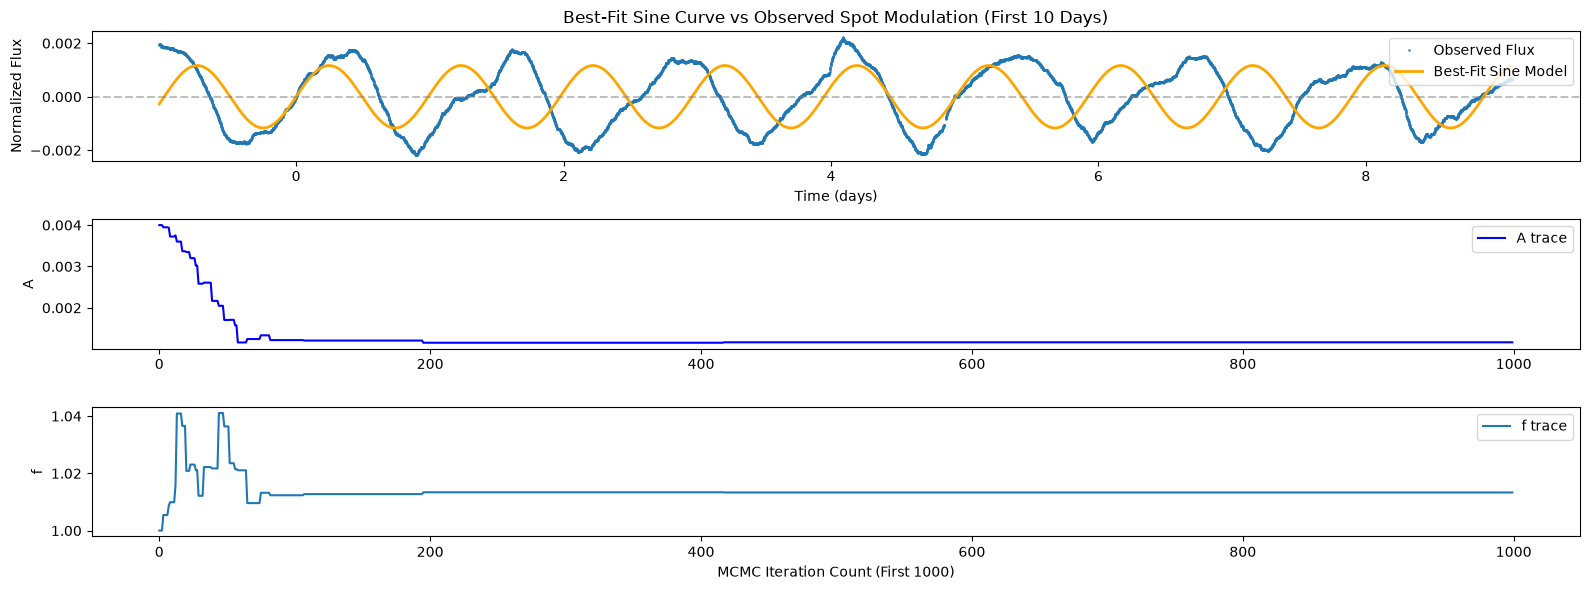

In [27]:
fig, ax = plt.subplots(3,1, figsize=(16, 6), sharey=False, sharex = False)  # Two side-by-side plots

#Best-fit model after MCMC
best_fit_flux = modelFunc(shifted_spot_time, A, f)

#Mask for first 10 days
mask = shifted_spot_time <= 10

#Plot observed flux and best-fit sine curve
ax[0].plot(shifted_spot_time[mask], spot_flux1[mask], '.', markersize=2, label='Observed Flux', alpha=0.7)
ax[0].plot(shifted_spot_time[mask], best_fit_flux[mask], '-', linewidth=2, label='Best-Fit Sine Model', color='orange')
ax[0].set_xlabel('Time (days)')
ax[0].set_ylabel('Normalized Flux')
ax[0].set_title('Best-Fit Sine Curve vs Observed Spot Modulation (First 10 Days)')
ax[0].axhline(0, linestyle='--', color='gray', alpha=0.5)
ax[0].legend()

ax[1].plot(A_array[:1000], color = "blue", label = "A trace")
ax[1].set_ylabel("A")
ax[1].legend()
ax[2].plot(f_array[:1000], label = "f trace")
ax[2].set_ylabel("f")
ax[2].set_xlabel("MCMC Iteration Count (First 1000)")
ax[2].legend()
fig.tight_layout()
plt.show()




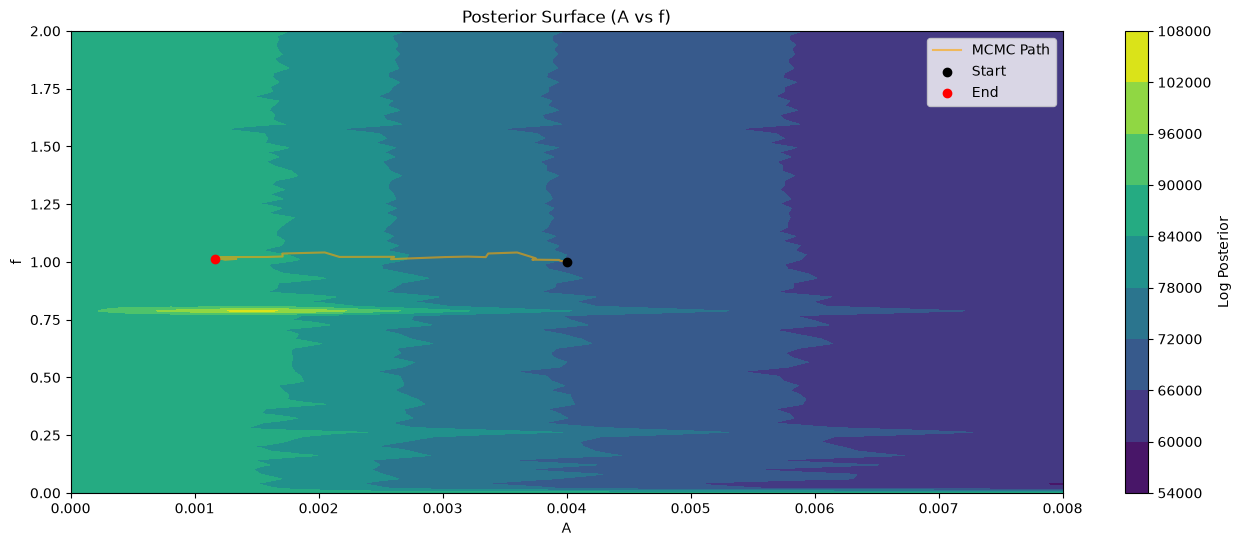

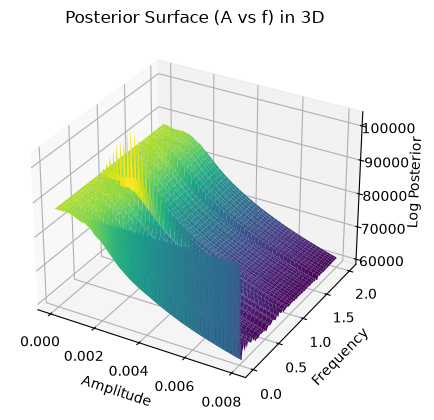

In [28]:
#I love my shared plots, so clean, so fancy
fig, ax = plt.subplots(1,1, figsize=(16, 6), sharey=False)  # Two side-by-side plots

#Linspace setup, some small ass numbers
A_vals = np.linspace(0, A_initial * 2, 100)
f_vals = np.linspace(0, f_initial * 2, 100)
A_grid, F_grid = np.meshgrid(A_vals, f_vals)
log_post_grid = np.zeros_like(A_grid)

#Calculate ALL values of the heat map via nested loop
for i in range(A_grid.shape[0]): #For each x
    for j in range(A_grid.shape[1]): #For each y
        A_test = A_grid[i, j]
        f_test = F_grid[i, j]

        # Prior
        prior = flat_prior(A_test, f_test)
        if prior == 0:
            log_post_grid[i, j] = -np.inf
        else:
            flux_model = modelFunc(shifted_spot_time, A_test, f_test)
            data_error = np.abs(spot_flux1 - flux_model)
            log_like = np.sum(np.log(norm.pdf(spot_flux1, flux_model, data_error)))
            log_post_grid[i, j] = log_like + np.log(prior)

#HEATMAP!
contour = ax.contourf(A_grid, F_grid, log_post_grid, cmap='viridis')
fig.colorbar(contour, ax=ax, label='Log Posterior')  # Colorbar for the heatmap
ax.set_title("Posterior Surface (A vs f)")
ax.set_xlabel("A")
ax.set_ylabel("f")

#path map from our starting values
ax.plot(A_array, f_array, alpha=0.6,color = "orange", label="MCMC Path")  
ax.scatter(A_array[0], f_array[0], color="black", label="Start", zorder=5)
ax.scatter(A_array[-1], f_array[-1], color="red", label="End", zorder=5)
ax.set_xlim(0, A_initial * 2)
ax.set_ylim(0, f_initial * 2)
ax.legend()

# Create a separate figure for the 3D plot
fig3D = plt.figure()
ax3D = fig3D.add_subplot(111, projection='3d')
ax3D.plot_surface(A_grid, F_grid, log_post_grid, cmap='viridis')
ax3D.set_xlabel('Amplitude')
ax3D.set_ylabel('Frequency')
ax3D.set_zlabel('Log Posterior')
ax3D.set_title('Posterior Surface (A vs f) in 3D')

plt.show()